In [1]:
import sys  
sys.path.insert(0, '/home/srinath/Documents/git/blind_watermark/blind_watermark')

import blind_watermark
from blind_watermark import WaterMark
from PIL import Image
import numpy as np
import matplotlib.pyplot as plt

# Embed the watermark

In [2]:
watermark_key = 'apple'
wat_length = (len(watermark_key)*8) - 1

rgb_filename = '/home/srinath/Documents/git/watermark-GAN-training-data/tmp/fp00000059.png'
# rgb_filename = '/home/srinath/Documents/git/watermark-GAN-training-data/tmp/fp00000059_gray_org.png'
output_filename = '/home/srinath/Documents/git/watermark-GAN-training-data/tmp/fp00000059_embed.png'
bwm1 = WaterMark(password_img=1, password_wm=1)
bwm1.read_img(rgb_filename)
wm = watermark_key
bwm1.read_wm(wm, mode='str')
bwm1.embed(output_filename)
print("Embeded")


Welcome to use blind-watermark, version = 0.4.1
Make sure the version is the same when encode and decode
Your star means a lot: https://github.com/guofei9987/blind_watermark
This message only show once. To close it: `blind_watermark.bw_notes.close()`
            
(512, 512, 3)
(512, 512, 3)
(512, 512, 3)
[256, 256]
Embeded


In [5]:
watermark_key = 'apple'
wat_length = (len(watermark_key)*8) - 1

rgb_filename = '/home/srinath/Documents/git/watermark-GAN-training-data/tmp/fp00000059.png'
# rgb_filename = '/home/srinath/Documents/git/watermark-GAN-training-data/tmp/fp00000059_gray_org.png'
output_filename = '/home/srinath/Documents/git/watermark-GAN-training-data/tmp/fp00000059_embed.png'

wm_img = '/home/srinath/Downloads/ovgu_64.png'

wm_img1 = '/home/srinath/Documents/git/dct_svd_in_dwt_watermark/assets/test_images/watermark_32_32.jpeg'

bwm1 = WaterMark(password_wm=1, password_img=1)
# read original image
bwm1.read_img(rgb_filename)
# read watermark
bwm1.read_wm(wm_img1)
# embed
bwm1.embed(output_filename)

print("Embeded")

(512, 512, 3)
1024
4096
Embeded


In [8]:
# Conver the rgb image to grayscale
input_filename = '/home/srinath/Documents/git/watermark-GAN-training-data/tmp/fp00000059.png'
rgb_filename = '/home/srinath/Documents/git/watermark-GAN-training-data/tmp/fp00000059_gray.png'
img = Image.open(input_filename)
grayimg = img.convert('L')
grayimg.paste(img)
grayimg.save(rgb_filename)

In [6]:
# Conver the rgb image to grayscale
input_filename = '/home/srinath/Documents/git/watermark-GAN-training-data/tmp/fp00000059_embed.png'
rgb_filename = '/home/srinath/Documents/git/watermark-GAN-training-data/tmp/fp00000059_embed_gray.png'
img = Image.open(input_filename)
grayimg = img.convert('L')
grayimg.paste(img)
grayimg.save(rgb_filename)

# Extract the watermark

In [10]:
embeded_img = '/home/srinath/Documents/git/watermark-GAN-training-data/tmp/fp00000059_embed_gray.png'
bwm1 = WaterMark(password_img=1, password_wm=1)
wm_extract = bwm1.extract(embeded_img, wm_shape=wat_length, mode='str')
print("Extracted watermark text: ", wm_extract)

Extracted watermark text:  apple


In [7]:
embeded_img = '/home/srinath/Documents/git/watermark-GAN-training-data/tmp/fp00000059_embed_gray.png'

bwm1 = WaterMark(password_wm=1, password_img=1)
# notice that wm_shape is necessary
bwm1.extract(filename=embeded_img, wm_shape=(32, 32), out_wm_name='output/extracted.png', )

(512, 512, 3)
1024
4096


array([[ 5.3125, 10.625 , 47.8125, ..., 79.6875, 26.5625, 26.5625],
       [10.625 ,  0.    , 21.25  , ..., 10.625 , 58.4375, 69.0625],
       [10.625 , 53.125 , 58.4375, ..., 58.4375, 26.5625, 42.5   ],
       ...,
       [26.5625, 21.25  , 58.4375, ...,  5.3125, 37.1875, 37.1875],
       [21.25  ,  5.3125, 47.8125, ..., 21.25  , 53.125 ,  0.    ],
       [26.5625, 15.9375, 47.8125, ..., 31.875 , 10.625 , 74.375 ]])

# Check the difference between the original image & wat image

In [11]:
input1 = '/home/srinath/Documents/git/watermark-GAN-training-data/tmp/fp00000059_gray.png'
input2 = '/home/srinath/Documents/git/watermark-GAN-training-data/tmp/fp00000059_embed_gray.png'

img1 = Image.open(input1)
img2 = Image.open(input2)

n_img1 = np.asarray(img1)
n_img2 = np.asarray(img2)

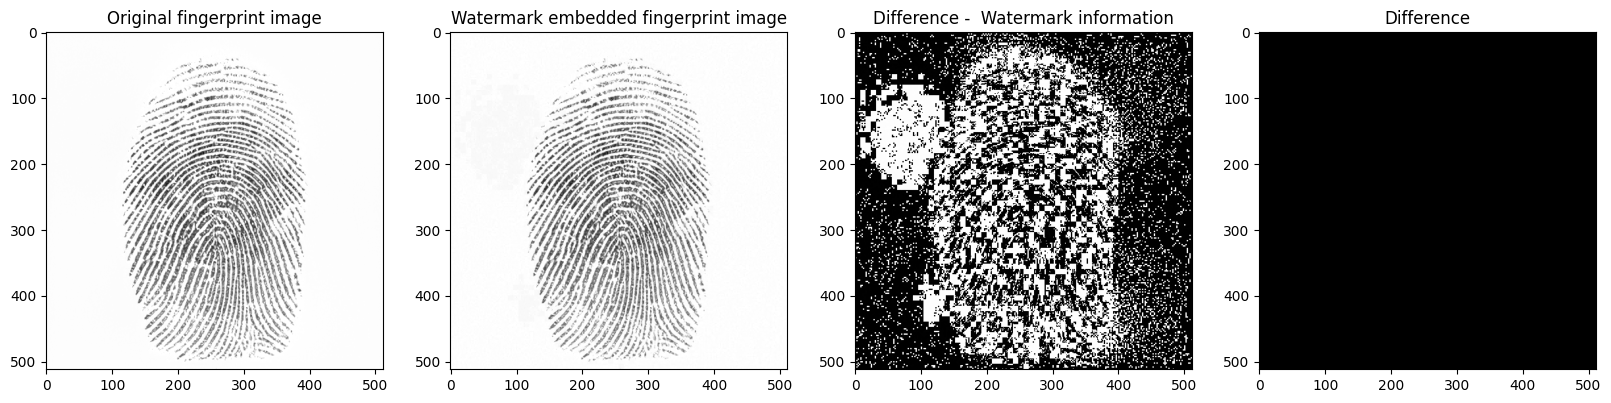

In [12]:
plt.figure(figsize=(20, 5))

# Plot original watermark image
ax = plt.subplot(1, 4, 1)
plt.imshow(n_img1)
plt.title( "Original fingerprint image")
plt.gray()

# Plot encrypted watermark image
ax = plt.subplot(1, 4, 2)
plt.imshow(n_img2)
plt.title( "Watermark embedded fingerprint image")
plt.gray()

# Plot encrypted watermark image
ax = plt.subplot(1, 4, 3)
plt.imshow(np.absolute(n_img2 - n_img1))
plt.title( "Difference -  Watermark information")
plt.gray()

ax = plt.subplot(1, 4, 4)
plt.imshow(np.absolute(n_img1 - n_img1))
plt.title( "Difference")
plt.gray()

plt.show()